# Forest Proximity Manifold ComparisonsThis notebook compares PHATE, UMAP, t-SNE, and Isomap embeddings on `datasets/treeData.csv` using proximity matrices from multiple forest backends including RandomForest, RotationForest, ObliqueRandomForest, HonestForest, PatchObliqueRandomForest, ExtendedIsolationForest, and IsolationForest.

In [ ]:
from forestgap import Proximity, embed, get_prototypes, impute, local_feature_importance, outlier_scoresclass _LegacyProximityModel:    def __init__(self, proximity):        self._proximity = proximity    def fit(self, X, y=None, **fit_kwargs):        self._proximity.fit(X, y, **fit_kwargs)        return self    def attach(self, X, y=None):        self._proximity.attach(X, y)        return self    def set_params(self, **params):        prox_params = {}        for key in ("relation", "prox_method", "matrix_type", "non_zero_diagonal", "symm_mode", "max_normalize", "random_state"):            if key in params:                prox_params[key] = params.pop(key)        if params:            self._proximity.estimator.set_params(**params)        if "prox_method" in prox_params and "relation" not in prox_params:            prox_params["relation"] = prox_params.pop("prox_method")        if prox_params:            rel = prox_params.get("relation", self._proximity.relation)            self._proximity._init_sparse_proximity(                prox_method=rel,                matrix_type=prox_params.get("matrix_type", self._proximity.matrix_type),                non_zero_diagonal=prox_params.get("non_zero_diagonal", self._proximity.non_zero_diagonal),                symm_mode=prox_params.get("symm_mode", self._proximity.symm_mode),                max_normalize=prox_params.get("max_normalize", self._proximity.max_normalize),            )            if "random_state" in prox_params:                self._proximity.random_state = prox_params["random_state"]        return self    def get_params(self, deep=True):        params = {}        try:            params.update(self._proximity.estimator.get_params(deep=deep))        except Exception:            pass        params.update({            "relation": self._proximity.relation,            "prox_method": self._proximity.relation,            "matrix_type": self._proximity.matrix_type,            "non_zero_diagonal": self._proximity.non_zero_diagonal,            "symm_mode": self._proximity.symm_mode,            "max_normalize": self._proximity.max_normalize,        })        return params    def phate(self, **kwargs):        return embed(self._proximity, method="phate", **kwargs)    def outlier_scores(self, *args, **kwargs):        return outlier_scores(self._proximity, *args, **kwargs)    def impute(self, *args, **kwargs):        return impute(self._proximity, *args, **kwargs)    def get_prototypes(self, *args, **kwargs):        return get_prototypes(self._proximity, *args, **kwargs)    def local_feature_importance(self, *args, **kwargs):        return local_feature_importance(self._proximity, *args, **kwargs)    def local_variable_importance(self, *args, **kwargs):        return local_feature_importance(self._proximity, *args, **kwargs)    def __getattr__(self, name):        return getattr(self._proximity, name)def compose_proximity(estimator_or_cls):    if isinstance(estimator_or_cls, type):        def _factory(*args, **kwargs):            relation = kwargs.pop("relation", kwargs.pop("prox_method", "rfgap"))            matrix_type = kwargs.pop("matrix_type", "sparse")            non_zero_diagonal = kwargs.pop("non_zero_diagonal", False)            symm_mode = kwargs.pop("symm_mode", None)            max_normalize = kwargs.pop("max_normalize", False)            random_state = kwargs.pop("random_state", None)            estimator = estimator_or_cls(*args, **kwargs)            prox = Proximity(                estimator,                relation=relation,                matrix_type=matrix_type,                non_zero_diagonal=non_zero_diagonal,                symm_mode=symm_mode,                max_normalize=max_normalize,                random_state=random_state,            )            return _LegacyProximityModel(prox)        return _factory    prox = Proximity(estimator_or_cls)    return _LegacyProximityModel(prox)

In [1]:
from pathlib import Pathimport sysimport warningsimport matplotlib.pyplot as pltimport numpy as npimport pandas as pdfrom sklearn.ensemble import IsolationForest, RandomForestClassifierwarnings.filterwarnings("ignore", category=FutureWarning)warnings.filterwarnings("ignore", message=".*OOB scores.*", category=UserWarning)PROJECT_ROOT = Path.cwd()if not (PROJECT_ROOT / "datasets" / "treeData.csv").exists():    PROJECT_ROOT = PROJECT_ROOT.parentsys.path.insert(0, str(PROJECT_ROOT))try:    from aeon.classification.sklearn import RotationForestClassifierexcept ImportError:    RotationForestClassifier = Nonetry:    from treeple import ObliqueRandomForestClassifierexcept ImportError:    ObliqueRandomForestClassifier = Nonetry:    from treeple import HonestForestClassifierexcept ImportError:    HonestForestClassifier = Nonetry:    from treeple import ExtendedIsolationForestexcept ImportError:    ExtendedIsolationForest = Nonetry:    from treeple import PatchObliqueRandomForestClassifierexcept ImportError:    PatchObliqueRandomForestClassifier = None

In [2]:
data_path = PROJECT_ROOT / "datasets" / "treeData.csv"tree_data = pd.read_csv(data_path)X = tree_data.drop(columns="branch")y = tree_data["branch"].astype(int)print(f"Loaded {data_path.relative_to(PROJECT_ROOT)}")print(f"X shape: {X.shape}")print("Branch counts:")print(y.value_counts().sort_index().to_string())

Loaded datasets\treeData.csv
X shape: (1440, 60)
Branch counts:
branch
1     180
2     140
3     140
4     140
5     140
6     140
7     140
8     140
9     140
10    140


In [3]:
backend_specs = [    {        "name": "RandomForest",        "base_cls": RandomForestClassifier,        "fit_supervised": True,        "forest_kwargs": {            "n_estimators": 120,            "random_state": 42,            "bootstrap": True,            "n_jobs": -1,        },        "prox_kwargs": {            "prox_method": "rfgap",            "matrix_type": "sparse",            "non_zero_diagonal": True,        },    },    {        "name": "RotationForest",        "base_cls": RotationForestClassifier,        "fit_supervised": True,        "forest_kwargs": {            "n_estimators": 80,            "random_state": 42,            "n_jobs": -1,        },        "prox_kwargs": {            "prox_method": "rfgap",            "matrix_type": "sparse",            "non_zero_diagonal": True,        },    },    {        "name": "ObliqueRandomForest",        "base_cls": ObliqueRandomForestClassifier,        "fit_supervised": True,        "forest_kwargs": {            "n_estimators": 120,            "random_state": 42,            "bootstrap": True,            "n_jobs": -1,        },        "prox_kwargs": {            "prox_method": "rfgap",            "matrix_type": "sparse",            "non_zero_diagonal": True,        },    },    {        "name": "HonestForest",        "base_cls": HonestForestClassifier,        "fit_supervised": True,        "forest_kwargs": {            "n_estimators": 80,            "random_state": 42,            "bootstrap": True,            "n_jobs": -1,        },        "prox_kwargs": {            "prox_method": "rfgap",            "matrix_type": "sparse",            "non_zero_diagonal": True,        },    },    {        "name": "PatchObliqueRandomForest",        "base_cls": PatchObliqueRandomForestClassifier,        "fit_supervised": True,        "forest_kwargs": {            "n_estimators": 120,            "random_state": 42,            "bootstrap": True,            "n_jobs": -1,        },        "prox_kwargs": {            "prox_method": "rfgap",            "matrix_type": "sparse",            "non_zero_diagonal": True,        },    },    {        "name": "ExtendedIsolationForest",        "base_cls": ExtendedIsolationForest,        "fit_supervised": False,        "forest_kwargs": {            "n_estimators": 120,            "random_state": 42,            "n_jobs": -1,        },        "prox_kwargs": {            "prox_method": "original",            "matrix_type": "sparse",            "non_zero_diagonal": True,        },    },    {        "name": "IsolationForest",        "base_cls": IsolationForest,        "fit_supervised": False,        "forest_kwargs": {            "n_estimators": 120,            "random_state": 42,            "n_jobs": -1,        },        "prox_kwargs": {            "prox_method": "original",            "matrix_type": "sparse",            "non_zero_diagonal": True,        },    },]backend_specs = [spec for spec in backend_specs if spec["base_cls"] is not None]embedding_specs = [    ("PHATE", {"method": "phate", "n_components": 2, "knn": 15, "t": "auto", "n_landmark": 300, "beta": 0.9, "verbose": 0}),    ("UMAP", {"method": "umap", "n_components": 2, "n_neighbors": 15, "min_dist": 0.1, "symm_mode": "arithmetic"}),    ("t-SNE", {"method": "tsne", "n_components": 2, "perplexity": 30, "learning_rate": "auto", "max_iter": 750, "symm_mode": "arithmetic"}),    ("Isomap", {"method": "isomap", "n_components": 2, "n_neighbors": 15, "symm_mode": "arithmetic"}),]print("Forest backends:")for spec in backend_specs:    print(f"- {spec['name']}")

Forest backends:
- RandomForest
- ObliqueRandomForest
- HonestForest
- PatchObliqueRandomForest
- ExtendedIsolationForest
- IsolationForest


In [4]:
import timefitted_forests = {}all_embeddings = {}runtime_rows = []for spec in backend_specs:    ProxForest = compose_proximity(spec["base_cls"])    forest = ProxForest(**spec["forest_kwargs"], **spec["prox_kwargs"])    print(f"Fitting {spec['name']}...")    fit_start = time.perf_counter()    if spec["fit_supervised"]:        forest.fit(X, y)    else:        forest.fit(X)    fit_seconds = time.perf_counter() - fit_start    fitted_forests[spec["name"]] = forest    all_embeddings[spec["name"]] = {}    embed_total_seconds = 0.0    for method_name, method_kwargs in embedding_specs:        print(f"  {method_name}")        embed_start = time.perf_counter()        all_embeddings[spec["name"]][method_name] = forest.embed(**method_kwargs)        embed_total_seconds += time.perf_counter() - embed_start    runtime_rows.append(        {            "backend": spec["name"],            "fit_seconds": fit_seconds,            "embed_seconds": embed_total_seconds,            "total_seconds": fit_seconds + embed_total_seconds,        }    )summary = {    backend_name: {method_name: emb.shape for method_name, emb in methods.items()}    for backend_name, methods in all_embeddings.items()}runtime_df = pd.DataFrame(runtime_rows).sort_values("total_seconds", ascending=False)print("\nRuntime summary (seconds):")print(runtime_df.to_string(index=False, float_format=lambda x: f"{x:.2f}"))summary

Fitting RandomForest...
  PHATE
    SGD-MDS may not have converged: stress changed by -4.1% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  UMAP


c:\Users\rhodes8\My Drive\repos\Oblique-RF-PHATE\GeneralForestProximities\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\rhodes8\My Drive\repos\Oblique-RF-PHATE\GeneralForestProximities\.venv\Lib\site-packages\umap\umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")
c:\Users\rhodes8\My Drive\repos\Oblique-RF-PHATE\GeneralForestProximities\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  t-SNE
  Isomap
Fitting ObliqueRandomForest...
  PHATE
    SGD-MDS may not have converged: stress changed by 3.0% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  UMAP


c:\Users\rhodes8\My Drive\repos\Oblique-RF-PHATE\GeneralForestProximities\.venv\Lib\site-packages\umap\umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")
c:\Users\rhodes8\My Drive\repos\Oblique-RF-PHATE\GeneralForestProximities\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  t-SNE
  Isomap
Fitting HonestForest...
  PHATE
    SGD-MDS may not have converged: stress changed by -3.0% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  UMAP


...

c:\Users\rhodes8\My Drive\repos\Oblique-RF-PHATE\GeneralForestProximities\.venv\Lib\site-packages\umap\umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")
c:\Users\rhodes8\My Drive\repos\Oblique-RF-PHATE\GeneralForestProximities\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  t-SNE
  Isomap
Fitting IsolationForest...
  PHATE
    SGD-MDS may not have converged: stress changed by -3.6% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  UMAP


c:\Users\rhodes8\My Drive\repos\Oblique-RF-PHATE\GeneralForestProximities\.venv\Lib\site-packages\umap\umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")
c:\Users\rhodes8\My Drive\repos\Oblique-RF-PHATE\GeneralForestProximities\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  t-SNE
  Isomap

Runtime summary (seconds):
                 backend  fit_seconds  embed_seconds  total_seconds
            RandomForest         0.24          21.45          21.68
 ExtendedIsolationForest         0.22           9.13           9.35
         IsolationForest         0.16           7.85           8.01
            HonestForest         1.54           5.22           6.75
PatchObliqueRandomForest         0.25           5.63           5.87
     ObliqueRandomForest         0.27           5.33           5.60


{'RandomForest': {'PHATE': (1440, 2),
  'UMAP': (1440, 2),
  't-SNE': (1440, 2),
  'Isomap': (1440, 2)},
 'ObliqueRandomForest': {'PHATE': (1440, 2),
  'UMAP': (1440, 2),
  't-SNE': (1440, 2),
  'Isomap': (1440, 2)},
 'HonestForest': {'PHATE': (1440, 2),
  'UMAP': (1440, 2),
  't-SNE': (1440, 2),
  'Isomap': (1440, 2)},
 'PatchObliqueRandomForest': {'PHATE': (1440, 2),
  'UMAP': (1440, 2),
  't-SNE': (1440, 2),
  'Isomap': (1440, 2)},
 'ExtendedIsolationForest': {'PHATE': (1440, 2),
  'UMAP': (1440, 2),
  't-SNE': (1440, 2),
  'Isomap': (1440, 2)},
 'IsolationForest': {'PHATE': (1440, 2),
  'UMAP': (1440, 2),
  't-SNE': (1440, 2),
  'Isomap': (1440, 2)}}

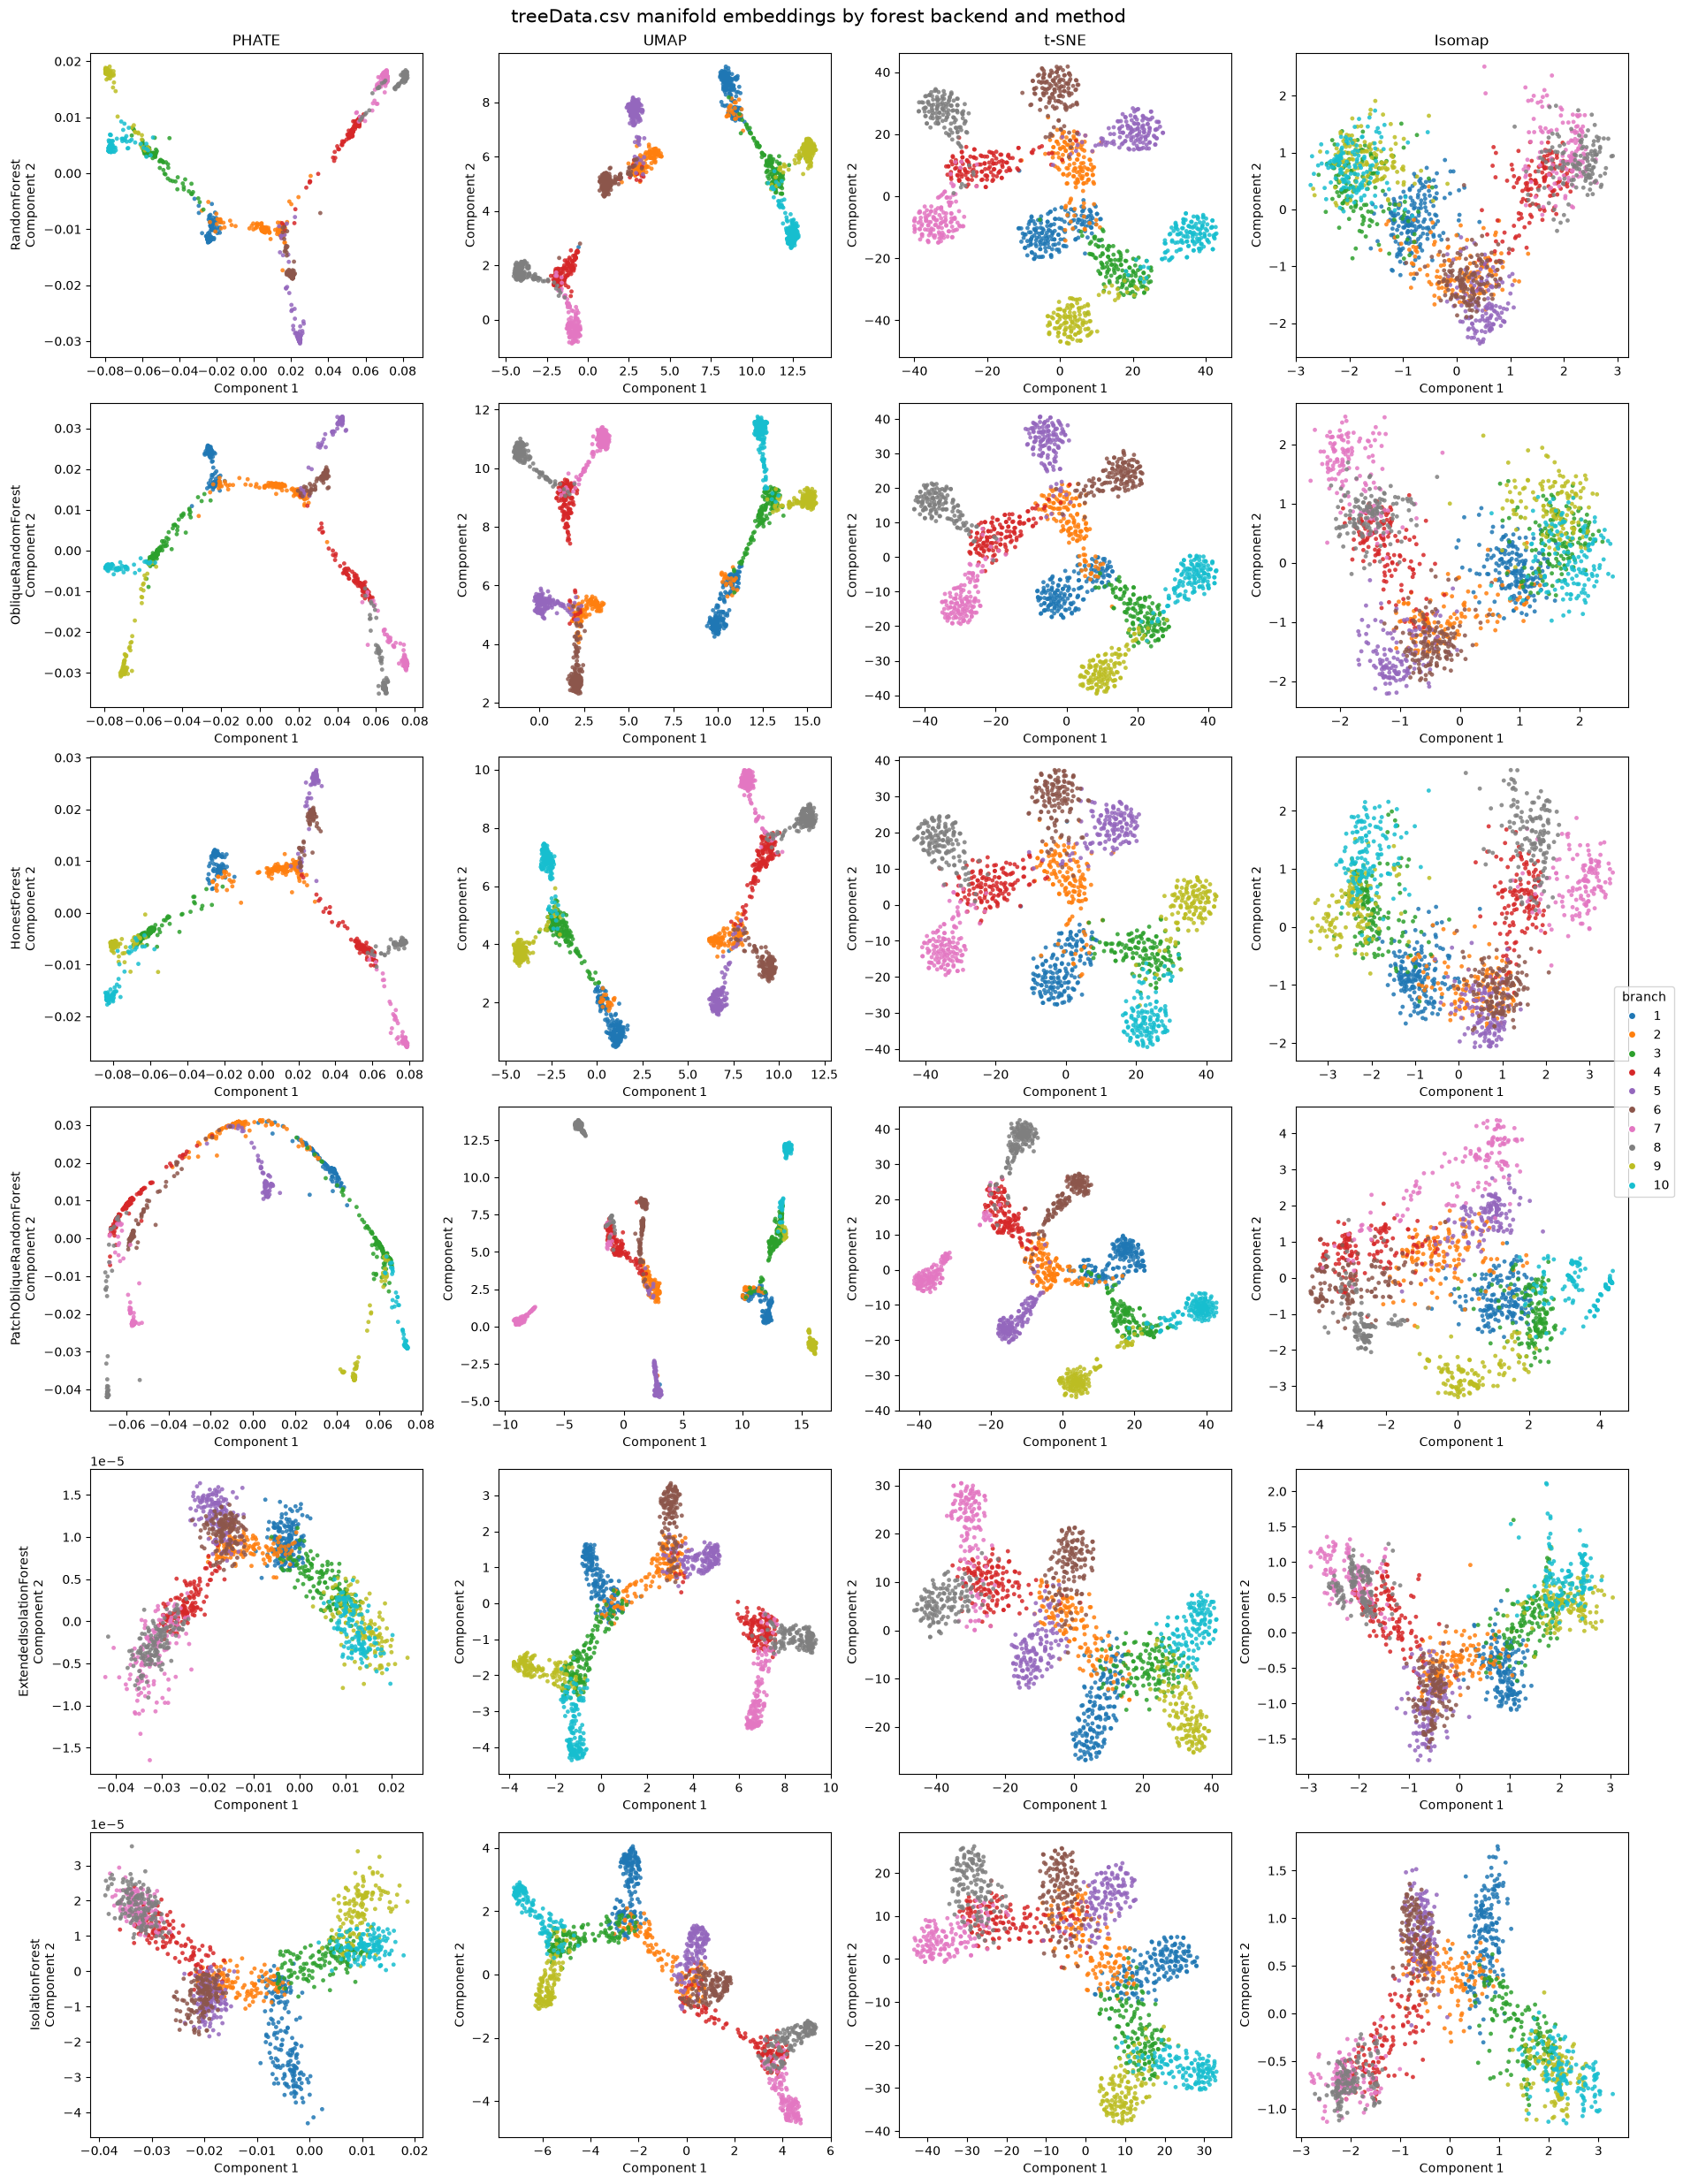

In [5]:
n_rows = len(backend_specs)n_cols = len(embedding_specs)fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.6 * n_cols, 4.1 * n_rows), constrained_layout=True)if n_rows == 1:    axes = np.array([axes])branches = np.sort(y.unique())cmap = plt.get_cmap("tab10", len(branches))for row_idx, spec in enumerate(backend_specs):    backend_name = spec["name"]    for col_idx, (method_name, _) in enumerate(embedding_specs):        ax = axes[row_idx, col_idx]        emb = all_embeddings[backend_name][method_name]        ax.scatter(            emb[:, 0],            emb[:, 1],            c=y,            cmap=cmap,            s=12,            alpha=0.85,            linewidths=0,        )        if row_idx == 0:            ax.set_title(method_name)        if col_idx == 0:            ax.set_ylabel(f"{backend_name}\nComponent 2")        else:            ax.set_ylabel("Component 2")        ax.set_xlabel("Component 1")handles = [    plt.Line2D(        [0],        [0],        marker="o",        color="w",        label=str(branch),        markerfacecolor=cmap(i),        markersize=6,    )    for i, branch in enumerate(branches)]fig.legend(handles=handles, title="branch", loc="center right", bbox_to_anchor=(1.03, 0.5))fig.suptitle("treeData.csv manifold embeddings by forest backend and method", fontsize=15)plt.show()